# 3 — GLM specifications and claim-level diagnostics

Extends the frozen experiment without new LLM calls or changes to Notebooks 0–2.
The primary model remains Gamma(log link) for **Y = log(1 + Loss)** with a numeric
severity label. Sensitivities replace that label with categorical indicators and,
separately, fit Gamma(log link) directly to positive dollar losses. All models use
the original split and the same eight peril indicators.

This notebook reads the frozen CSVs directly from the local `data/` and `tables/`
directories. It verifies input hashes and
the original 30 regression results. Outputs go to `tables/glm_extensions/`;
the final cells generate manuscript appendix tables and short results passages.
No credentials or network access are required.

The prediction-agreement extension compares all 30 primary validation prediction vectors within and between LLMs, as well as their five-run averages. It adds tied-rank risk-decile changes, fractional allocation sensitivity, paired rerun references, and a coefficient-locking diagnostic. All predictions concern the same 1,039 validation claims.

Generated prose and tables update marked sections directly in `paper_naaj/manuscript_body.tex` and the single `paper_naaj/appendix.tex`. No separate TeX fragments are written. Analytical artifact manifests cover the notebook outputs; the shared manuscript sources are versioned separately.

The compact primary appendix is rendered by `paper_reporting.py`; complete supporting outputs are indexed in `SUPPLEMENT.md`.

**Paper coverage:** §§3.3 and 4.2; Appendix A.1–A.3 (Tables A1–A5).

Use the pinned environment in [README.md](README.md#run-the-analysis). Run cells from top to bottom; saved inference caches allow reproduction without API keys or new requests.


In [1]:
from pathlib import Path
from itertools import combinations
from importlib.metadata import version
import hashlib
import io
import json
import platform

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_gamma_deviance
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 's0_get_data.ipynb').exists())
import sys
sys.path.insert(0, str(ROOT))
from manuscript_sections import update_section
from paper_reporting import write_primary_appendix
OUT = ROOT / 'tables' / 'glm_extensions'
OUT.mkdir(parents=True, exist_ok=True)
PAPER = ROOT / 'paper_naaj'
EXPECTED_HASHES = {
    'data/raw/peril.training.csv': '8592694291bc9cbdce5bd2a33683c5ca961e6db45937830955f180ff3e8e1cc5',
    'data/raw/peril.validation.csv': '7734dfd42d51dec22c5b063e53032f7c62143729c9980b4f74028ab738f45653',
    'data/processed/claims.csv': '606128c7d2dd87d98a4f875a7e9b2c9bc63cc0e76a166794d106f6513c03fe76',
    'data/results/classifications.csv': '478d5dac8da70df7e7fe2f879f6b1d50735d61aed1b2fde7ee9e2081e7149c7a',
    'tables/model_roster.csv': '0df0c57a3b2a9ef9d908ac7abaad3a640dae6013bfe774231b8271bb8737b3cf',
    'tables/performance_by_run.csv': '88129a6c04c74871b4b6582570ab972cad0ce77ecf345504d5d7542b6635d1e8',
}
input_manifest = []
def read_frozen(relative):
    path = ROOT / relative
    data = path.read_bytes()
    digest = hashlib.sha256(data).hexdigest()
    assert digest == EXPECTED_HASHES[relative], f'Frozen input changed: {relative}'
    input_manifest.append({'input': relative, 'source': relative, 'sha256': digest})
    return pd.read_csv(io.BytesIO(data))

claims = read_frozen('data/processed/claims.csv')
raw_train = read_frozen('data/raw/peril.training.csv')
raw_valid = read_frozen('data/raw/peril.validation.csv')
raw_claims = pd.concat([raw_train, raw_valid], ignore_index=True)
assert len(raw_claims) == len(claims)
assert np.array_equal(raw_claims.Loss.to_numpy(), claims.Loss.to_numpy())
assert raw_claims.Description.fillna('').astype(str).str.strip().tolist() == claims.Description.tolist()
labels = read_frozen('data/results/classifications.csv')
roster = read_frozen('tables/model_roster.csv')
original_performance = read_frozen('tables/performance_by_run.csv')
claims.insert(0, 'claim_row', np.arange(len(claims)))
MODELS = roster['model'].tolist()
RUNS = sorted(labels['run'].unique())
PERILS = ['Vandalism', 'Fire', 'Lightning', 'Wind', 'Hail', 'Vehicle', 'WaterNW', 'WaterW']
LABEL_NAMES = ['negligible', 'low', 'medium', 'high', 'catastrophic']
assert len(claims) == 6030 and len(labels) == 140700
assert not labels.duplicated(['description_id', 'model', 'run']).any()
assert labels.label_value.isin(range(1, 6)).all()
assert np.allclose(claims.log_loss, np.log1p(claims.Loss), rtol=0, atol=1e-12)
assert claims[PERILS + ['Misc']].sum(axis=1).eq(1).all()
pd.DataFrame(input_manifest).to_csv(OUT / 'input_manifest.csv', index=False)
environment = {'python': platform.python_version(), **{p: version(p) for p in ['numpy', 'pandas', 'scipy', 'statsmodels', 'scikit-learn']}}
(OUT / 'environment.json').write_text(json.dumps(environment, indent=2) + '\n')
display(pd.DataFrame(input_manifest))
display(pd.Series(environment, name='version'))


,input,source,sha256
0,data/processed/claims.csv,data/processed/claims.csv,606128c7d2dd87d98a4f875a7e9b2c9bc63cc0e76a1667...
1,data/raw/peril.training.csv,data/raw/peril.training.csv,8592694291bc9cbdce5bd2a33683c5ca961e6db4593783...
2,data/raw/peril.validation.csv,data/raw/peril.validation.csv,7734dfd42d51dec22c5b063e53032f7c62143729c9980b...
3,data/results/classifications.csv,data/results/classifications.csv,478d5dac8da70df7e7fe2f879f6b1d50735d61aed1b2fd...
4,tables/model_roster.csv,tables/model_roster.csv,0df0c57a3b2a9ef9d908ac7abaad3a640dae6013bfe774...
5,tables/performance_by_run.csv,tables/performance_by_run.csv,88129a6c04c74871b4b6582570ab972cad0ce77ecf3455...


python          3.12.11
numpy             2.4.3
pandas            2.3.3
scipy            1.17.1
statsmodels      0.14.6
scikit-learn      1.8.0
Name: version, dtype: object

## Response support, R², and metric definitions

The Gamma response must be positive. We audit both source losses and transformed
losses and **fail** if either has nonpositive values; there is no clipping,
pseudocount beyond the published `log1p`, or deletion. These claims all have Loss ≥ 1.

The reported R² is `1 − sum((Y − prediction)²) / sum((Y − mean(Y))²)`, calculated
separately within the evaluation split. This is a predictive sum-of-squares score,
not a likelihood/deviance pseudo-R², and it can be negative.

Log MAE preserves comparability and downweights large dollar errors. It does not
measure adequacy of dollar reserves. For retrospective triage ranking we report:

* Spearman correlation between predictions and realized dollar loss;
* normalized Gini: `1 − 2 × area under the ascending-score concentration curve`,
  divided by the same statistic for perfect ranking by realized loss;
* top-decile lift: realized mean dollar loss in the highest-scoring 10% divided
  by the overall mean dollar loss. Exactly 10% of claim mass is selected,
  allocating fractional weight to ties at the boundary. Gini groups exact score
  ties before integration, so neither statistic depends on claim row order.

For the primary log-response model, `expm1(prediction)` is reported only as an
inverse-transformed point score: it is **not** E(Loss | X). A Gamma response on
the log scale needs an explicit retransformation calculation to target dollar means.
We instead also refit the same designs directly to positive dollar losses,
and report dollar MAE, RMSE, Gamma deviance, and aggregate predicted/observed
loss. These are distinct mean specifications, not a bias correction to the
published model. No validation losses are used to calibrate predictions.

References: [statsmodels Gamma support](https://www.statsmodels.org/stable/glm.html),
[R² definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html),
[insurance ranking and calibration](https://scikit-learn.org/stable/auto_examples/linear_model/plot_tweedie_regression_insurance_claims.html).

**Reports:** §3.3; response support and metric definitions.


In [2]:
support = claims.groupby('split', sort=False).agg(
    claims=('Loss', 'size'), minimum_loss=('Loss', 'min'),
    minimum_log_loss=('log_loss', 'min'),
    zero_losses=('Loss', lambda s: int((s == 0).sum())),
    zero_transformed_losses=('log_loss', lambda s: int((s == 0).sum())),
)
assert (claims.Loss > 0).all() and (claims.log_loss > 0).all()
support.to_csv(OUT / 'response_support.csv')
display(support)

def concentration_gini(loss, score):
    frame = pd.DataFrame({'loss': np.asarray(loss, float), 'score': np.asarray(score, float)})
    grouped = frame.groupby('score', sort=True).agg(loss=('loss', 'sum'), n=('loss', 'size'))
    x = np.r_[0.0, grouped.n.cumsum().to_numpy() / len(frame)]
    y = np.r_[0.0, grouped.loss.cumsum().to_numpy() / frame.loss.sum()]
    return float(1 - 2 * np.trapezoid(y, x))

def top_weights(score, fraction=0.10):
    score = np.asarray(score, float)
    mass = len(score) * fraction
    cutoff = np.sort(score)[::-1][int(np.ceil(mass)) - 1]
    weights = (score > cutoff).astype(float)
    ties = score == cutoff
    weights[ties] = (mass - weights.sum()) / ties.sum()
    assert np.isclose(weights.sum(), mass)
    return weights

def ranking_metrics(loss, score):
    loss, score = np.asarray(loss, float), np.asarray(score, float)
    perfect = concentration_gini(loss, loss)
    weights = top_weights(score)
    return {
        'spearman': float(spearmanr(loss, score).statistic),
        'normalized_gini': concentration_gini(loss, score) / perfect,
        'top_decile_lift': float(np.dot(weights, loss) / weights.sum() / loss.mean()),
        'top_decile_loss_share': float(np.dot(weights, loss) / loss.sum()),
    }

def evaluate(frame, prediction, target):
    observed = frame['log_loss' if target == 'log_loss' else 'Loss'].to_numpy()
    prediction = np.asarray(prediction, float)
    assert np.isfinite(prediction).all() and (prediction > 0).all()
    r2 = 1 - np.square(observed - prediction).sum() / np.square(observed - observed.mean()).sum()
    assert np.isclose(r2, r2_score(observed, prediction))
    result = {
        'mae_response': np.abs(observed - prediction).mean(),
        'rmse_response': np.sqrt(np.square(observed - prediction).mean()),
        'r2_response': r2,
        'gamma_deviance_response': mean_gamma_deviance(observed, prediction),
        **ranking_metrics(frame.Loss, prediction),
    }
    dollars = np.expm1(prediction) if target == 'log_loss' else prediction
    assert np.isfinite(dollars).all()
    result.update({
        'dollar_mae': np.abs(frame.Loss.to_numpy() - dollars).mean(),
        'dollar_rmse': np.sqrt(np.square(frame.Loss.to_numpy() - dollars).mean()),
        'dollar_predicted_observed': dollars.sum() / frame.Loss.sum(),
        'dollar_prediction_type': 'inverse_log_point_score' if target == 'log_loss' else 'direct_gamma_mean',
    })
    return result

# Meaningful metric checks: perfect/constant rankings, ties, and scale invariance.
test_y = np.array([1., 2., 4., 8., 16.])
assert np.isclose(ranking_metrics(test_y, test_y)['normalized_gini'], 1)
assert np.isclose(concentration_gini(test_y, np.ones(5)), 0)
constant_weights = top_weights(np.ones(5))
assert np.isclose(np.dot(constant_weights, test_y) / constant_weights.sum() / test_y.mean(), 1)
test_score = np.array([1., 1., 3., 3., 3.])
order = np.array([4, 1, 3, 0, 2])
assert np.isclose(concentration_gini(test_y, test_score), concentration_gini(test_y[order], test_score[order]))
assert np.isclose(np.dot(top_weights(test_score), test_y), np.dot(top_weights(test_score[order]), test_y[order]))
assert np.isclose(concentration_gini(test_y, test_score), concentration_gini(test_y, np.exp(test_score)))
pairwise_gini = np.sum(np.sign(test_score[:, None] - test_score[None, :])
                       * (test_y[:, None] - test_y[None, :])) / (2 * len(test_y) * test_y.sum())
assert np.isclose(concentration_gini(test_y, test_score), pairwise_gini)
print('Metric definitions and tie-handling checks passed.')


,claims,minimum_loss,minimum_log_loss,zero_losses,zero_transformed_losses
split,,,,,
train,4991,1.0,0.693147,0,0
validation,1039,1.0,0.693147,0,0


Metric definitions and tie-handling checks passed.


## Numeric and categorical Gamma fits

The numeric model adds one coefficient γ per model/run. The categorical model adds
indicators for low, medium, high and catastrophic, with negligible as reference;
it relaxes equal spacing on the **linear predictor** scale. It has three more
estimable parameters when all five categories occur. An absent training category
is not estimated; the notebook stops if that category occurs in validation.
No labels are pooled and no arbitrary coefficient is assigned to an unseen level.

All 30 primary γ estimates receive the ordinary model-based SE (estimated Pearson
dispersion, as in the existing fits) and an additional description-clustered SE
with a finite-sample correction. Both condition on the observed labels and training
sample; neither is the standard deviation over LLM reruns. The clustered SE allows
dependence among training claims sharing the same description.

**Reports:** Appendix A.1–A.2; Tables A1–A3.


In [3]:
predictions, fits = {}, {}
coefficient_rows, gamma_rows, metric_rows, validation_rows, category_rows = [], [], [], [], []

def design(frame, coding, supported=None):
    x = sm.add_constant(frame[PERILS].astype(float), has_constant='add')
    if coding == 'numeric':
        x['label_value'] = frame.label_value.astype(float)
    elif coding == 'categorical':
        for level in supported:
            if level != 1:
                x[f'severity_{level}'] = frame.label_value.eq(level).astype(float)
    return x

def fit_one(data, model, run, coding, target):
    train = data.loc[data.split.eq('train')].copy()
    valid = data.loc[data.split.eq('validation')].copy()
    supported = sorted(train.label_value.unique()) if coding != 'baseline' else None
    if coding == 'categorical':
        assert 1 in supported
        assert valid.label_value.isin(supported).all(), 'Unseen validation level: no estimable categorical prediction'
    x_train, x_valid = design(train, coding, supported), design(valid, coding, supported)
    assert np.linalg.matrix_rank(x_train) == x_train.shape[1]
    response = train['log_loss' if target == 'log_loss' else 'Loss']
    glm = sm.GLM(response, x_train, family=sm.families.Gamma(link=sm.families.links.Log()))
    fit = glm.fit(maxiter=1000)
    assert fit.converged, (target, coding, model, run)
    assert np.isfinite(fit.params).all() and np.isfinite(fit.bse).all()
    key = (target, coding, model, int(run))
    fits[key] = fit
    prediction = np.asarray(fit.predict(x_valid))
    predictions[key] = prediction
    metric_rows.append({
        'target': target, 'coding': coding, 'model': model, 'run': run,
        'parameters': x_train.shape[1], 'training_deviance': fit.deviance,
        **evaluate(valid, prediction, target),
    })
    for term in fit.params.index:
        coefficient_rows.append({
            'target': target, 'coding': coding, 'model': model, 'run': run,
            'term': term, 'estimate': fit.params[term], 'standard_error': fit.bse[term],
            'dispersion': fit.scale, 'parameters': x_train.shape[1],
        })
    if target == 'log_loss' and coding == 'numeric':
        clustered = glm.fit(maxiter=1000, cov_type='cluster', cov_kwds={
            'groups': train.description_id.to_numpy(), 'use_correction': True,
        })
        assert np.allclose(fit.params, clustered.params, rtol=0, atol=1e-10)
        gamma_rows.append({
            'model': model, 'run': run, 'gamma': fit.params['label_value'],
            'model_based_se': fit.bse['label_value'],
            'description_clustered_se': clustered.bse['label_value'],
            'training_claims': len(train), 'training_descriptions': train.description_id.nunique(),
            'dispersion': fit.scale,
        })
    if target == 'log_loss' and coding == 'categorical':
        for level in range(1, 6):
            category_rows.append({
                'model': model, 'run': run, 'level': level, 'label': LABEL_NAMES[level - 1],
                'train_claims': int(train.label_value.eq(level).sum()),
                'validation_claims': int(valid.label_value.eq(level).sum()),
                'estimated': level in supported, 'reference': level == 1,
                'parameters': x_train.shape[1],
            })
    output = valid[['claim_row', 'description_id', 'Loss', 'log_loss']].copy()
    output['target'], output['coding'], output['model'], output['run'] = target, coding, model, run
    output['prediction_response'] = prediction
    output['prediction_dollars'] = np.expm1(prediction) if target == 'log_loss' else prediction
    output['dollar_prediction_type'] = 'inverse_log_point_score' if target == 'log_loss' else 'direct_gamma_mean'
    validation_rows.append(output)


### Fit, save, and reproduce the models

**Reports:** Tables A1–A3. The helper above handles both coding choices and response scales.


In [4]:
for target in ['log_loss', 'dollars']:
    fit_one(claims, 'No LLM feature', 0, 'baseline', target)
for model in MODELS:
    for run in RUNS:
        feature = labels.loc[labels.model.eq(model) & labels.run.eq(run), ['description_id', 'label_value']]
        data = claims.merge(feature, on='description_id', how='left', validate='many_to_one', sort=False)
        assert data.label_value.notna().all() and np.array_equal(data.claim_row, claims.claim_row)
        for target in ['log_loss', 'dollars']:
            for coding in ['numeric', 'categorical']:
                fit_one(data, model, run, coding, target)
    print('Completed', model)

performance = pd.DataFrame(metric_rows)
coefficients = pd.DataFrame(coefficient_rows)
gammas = pd.DataFrame(gamma_rows)
category_support = pd.DataFrame(category_rows)
validation_predictions = pd.concat(validation_rows, ignore_index=True)
assert len(performance) == 122 and len(gammas) == 30
assert (category_support.query('not estimated').validation_claims == 0).all()
performance.to_csv(OUT / 'performance_by_run.csv', index=False)
coefficients.to_csv(OUT / 'all_coefficients.csv', index=False)
gammas.to_csv(OUT / 'gamma_coefficients.csv', index=False)
category_support.to_csv(OUT / 'categorical_support.csv', index=False)
validation_predictions.to_csv(OUT / 'validation_predictions.csv', index=False)

metric_names = ['mae_response', 'rmse_response', 'r2_response', 'normalized_gini', 'spearman',
                'top_decile_lift', 'top_decile_loss_share', 'gamma_deviance_response',
                'dollar_mae', 'dollar_rmse', 'dollar_predicted_observed']
summary = performance.groupby(['target', 'coding', 'model'], sort=False)[metric_names].mean().reset_index()
summary.to_csv(OUT / 'performance_summary.csv', index=False)
reproduced = performance.query("target == 'log_loss' and coding == 'numeric'").merge(
    original_performance.query("split == 'validation'"), on=['model', 'run'], validate='one_to_one',
)
assert len(reproduced) == 30
for new, old in [('mae_response', 'mae'), ('r2_response', 'r2')]:
    assert np.allclose(reproduced[new], reproduced[old], rtol=0, atol=1e-11)
baseline_log_prediction = predictions[('log_loss', 'baseline', 'No LLM feature', 0)]
valid = claims.loc[claims.split.eq('validation')].copy().reset_index(drop=True)
assert abs(np.abs(valid.log_loss.to_numpy() - baseline_log_prediction).mean() - 1.0694) < 5e-5
print('All 30 published numeric-model regressions reproduced.')
display(gammas.round(5))
display(summary.round(4))
display(category_support.query('not estimated'))


Completed GPT-5.6 Sol


Completed Gemini 3.1 Pro


Completed Kimi K2.6


Completed DeepSeek V4 Pro


Completed Qwen3.5 397B


Completed GLM-5.2


All 30 published numeric-model regressions reproduced.


,model,run,gamma,model_based_se,description_clustered_se,training_claims,training_descriptions,dispersion
0,GPT-5.6 Sol,1,0.09270,0.00454,0.00565,4991,3733,0.03037
1,GPT-5.6 Sol,2,0.08495,0.00439,0.00564,4991,3733,0.03052
2,GPT-5.6 Sol,3,0.09311,0.00447,0.00557,4991,3733,0.03027
3,GPT-5.6 Sol,4,0.08956,0.00435,0.00693,4991,3733,0.03039
4,GPT-5.6 Sol,5,0.08802,0.00456,0.00500,4991,3733,0.03064
5,Gemini 3.1 Pro,1,0.07223,0.00373,0.00517,4991,3733,0.03043
6,Gemini 3.1 Pro,2,0.07158,0.00381,0.00504,4991,3733,0.03052
7,Gemini 3.1 Pro,3,0.07745,0.00381,0.00444,4991,3733,0.03025
8,Gemini 3.1 Pro,4,0.08393,0.00379,0.00464,4991,3733,0.02978
9,Gemini 3.1 Pro,5,0.07621,0.00381,0.00462,4991,3733,0.03025


,target,coding,model,mae_response,rmse_response,r2_response,normalized_gini,spearman,top_decile_lift,top_decile_loss_share,gamma_deviance_response,dollar_mae,dollar_rmse,dollar_predicted_observed
0,log_loss,baseline,No LLM feature,1.0694,1.4724,0.3398,0.6255,0.6158,3.4916,0.3492,0.0422,19280.2468,114043.8351,0.1844
1,dollars,baseline,No LLM feature,24893.2292,111757.9706,0.0281,0.5468,0.5608,3.4484,0.3448,3.6295,24893.2292,111757.9706,0.8457
2,log_loss,numeric,GPT-5.6 Sol,0.9906,1.3701,0.4283,0.7147,0.6768,5.3203,0.5320,0.0376,18856.8431,113073.3940,0.2246
3,log_loss,categorical,GPT-5.6 Sol,0.9915,1.3713,0.4273,0.7152,0.6772,5.2677,0.5268,0.0377,18644.0918,111307.1311,0.2479
4,dollars,numeric,GPT-5.6 Sol,23580.3901,109645.1637,0.0645,0.7022,0.6624,4.8913,0.4891,2.9615,23580.3901,109645.1637,0.8733
5,dollars,categorical,GPT-5.6 Sol,24143.4179,109863.2603,0.0607,0.7068,0.6589,5.0545,0.5055,2.9470,24143.4179,109863.2603,0.9482
6,log_loss,numeric,Gemini 3.1 Pro,0.9794,1.3614,0.4356,0.7246,0.6870,5.5793,0.5579,0.0374,18804.3171,112968.8669,0.2247
7,log_loss,categorical,Gemini 3.1 Pro,0.9800,1.3620,0.4351,0.7220,0.6854,5.2223,0.5222,0.0374,18777.8788,112617.8643,0.2261
8,dollars,numeric,Gemini 3.1 Pro,22805.4106,109197.6474,0.0721,0.7082,0.6764,4.6300,0.4630,2.9769,22805.4106,109197.6474,0.8729
9,dollars,categorical,Gemini 3.1 Pro,23752.0334,109658.3713,0.0640,0.7229,0.6773,5.5218,0.5522,2.9931,23752.0334,109658.3713,0.9641


,model,run,level,label,train_claims,validation_claims,estimated,reference,parameters
109,Qwen3.5 397B,2,5,catastrophic,0,0,False,False,12


## Coding sensitivity and claim-level output differences

Coding sensitivity is paired on validation claims and averaged over the five
saved LLM runs. Percentile intervals resample unique validation descriptions
2,000 times, retaining all associated claims and their weights. Intervals are
conditional on fitted training models and the five saved label runs.

For each coding and response scale we compare all 15 model pairs using each
claim's **mean prediction over the five separately refitted models**. This exposes
persistent output differences after refitting. We report mean/median/95th-percentile
absolute differences, Spearman agreement between predictions, and fractional
top-decile allocation overlap. The overlap is sum(min(wA, wB)) / (0.1 × n),
where w are the fractional selection weights defined above; it is not an observed
claims decision. We additionally retain differences over all 25 cross-model run
combinations and ten same-model run pairs. The primary six close-performance pairs
are identified using the original numeric/log-MAE tolerance, not selected by the
new prediction diagnostics.

**Reports:** §4.2 and Appendix A.2–A.3; Tables A2, A4–A5.


In [5]:
BOOTSTRAPS = 2000
rng = np.random.default_rng(20261104)
def cluster_mean_ci(values):
    grouped = pd.DataFrame({'description_id': valid.description_id, 'value': np.asarray(values)}).groupby('description_id').value.agg(['sum', 'size'])
    sums, counts = grouped['sum'].to_numpy(), grouped['size'].to_numpy()
    draws = rng.integers(0, len(grouped), size=(BOOTSTRAPS, len(grouped)))
    estimates = sums[draws].sum(axis=1) / counts[draws].sum(axis=1)
    return np.quantile(estimates, [0.025, 0.975])

sensitivity_rows = []
for model in MODELS:
    numeric_errors, categorical_errors = [], []
    for run in RUNS:
        numeric_errors.append(np.abs(valid.log_loss - predictions[('log_loss', 'numeric', model, run)]))
        categorical_errors.append(np.abs(valid.log_loss - predictions[('log_loss', 'categorical', model, run)]))
    delta = np.mean(categorical_errors, axis=0) - np.mean(numeric_errors, axis=0)
    lo, hi = cluster_mean_ci(delta)
    a = summary.query("target == 'log_loss' and coding == 'numeric' and model == @model").iloc[0]
    b = summary.query("target == 'log_loss' and coding == 'categorical' and model == @model").iloc[0]
    sensitivity_rows.append({
        'model': model, 'numeric_log_mae': a.mae_response, 'categorical_log_mae': b.mae_response,
        'categorical_minus_numeric_mae': delta.mean(), 'ci_low': lo, 'ci_high': hi,
        'numeric_log_r2': a.r2_response, 'categorical_log_r2': b.r2_response,
    })
coding_sensitivity = pd.DataFrame(sensitivity_rows)
coding_sensitivity.to_csv(OUT / 'coding_sensitivity.csv', index=False)

pair_rows, within_rows = [], []
mean_predictions = {}
for target in ['log_loss', 'dollars']:
    y = valid['log_loss' if target == 'log_loss' else 'Loss'].to_numpy()
    base_mae = np.abs(y - predictions[(target, 'baseline', 'No LLM feature', 0)]).mean()
    for coding in ['numeric', 'categorical']:
        model_maes = summary.query('target == @target and coding == @coding').set_index('model').mae_response
        for model in MODELS:
            runs = np.stack([predictions[(target, coding, model, run)] for run in RUNS])
            mean_predictions[(target, coding, model)] = runs.mean(axis=0)
            differences = np.stack([np.abs(runs[i] - runs[j]) for i, j in combinations(range(5), 2)])
            within_rows.append({'target': target, 'coding': coding, 'model': model,
                               'mean_abs_run_difference': differences.mean(),
                               'p95_abs_run_difference': np.quantile(differences, .95)})
        for model_a, model_b in combinations(MODELS, 2):
            a, b = mean_predictions[(target, coding, model_a)], mean_predictions[(target, coding, model_b)]
            distance = np.abs(a - b)
            run_distances = np.stack([
                np.abs(predictions[(target, coding, model_a, ra)] - predictions[(target, coding, model_b, rb)])
                for ra in RUNS for rb in RUNS
            ])
            same_scale_close = abs(model_maes[model_a] - model_maes[model_b]) < .01 * base_mae
            pair_rows.append({
                'target': target, 'coding': coding, 'model_a': model_a, 'model_b': model_b,
                'mean_mae_difference': abs(model_maes[model_a] - model_maes[model_b]),
                'mae_difference_pct_baseline': 100 * abs(model_maes[model_a] - model_maes[model_b]) / base_mae,
                'within_own_1pct_tolerance': same_scale_close,
                'mean_abs_mean_prediction_difference': distance.mean(),
                'median_abs_mean_prediction_difference': np.median(distance),
                'p95_abs_mean_prediction_difference': np.quantile(distance, .95),
                'max_abs_mean_prediction_difference': distance.max(),
                'prediction_spearman': spearmanr(a, b).statistic,
                'top_decile_fractional_overlap': np.minimum(top_weights(a), top_weights(b)).sum() / (.1 * len(valid)),
                'mean_abs_all_run_difference': run_distances.mean(),
                'p95_abs_all_run_difference': np.quantile(run_distances, .95),
            })
pairwise_predictions = pd.DataFrame(pair_rows)
within_predictions = pd.DataFrame(within_rows)
primary_pairs = pairwise_predictions.query("target == 'log_loss' and coding == 'numeric' and within_own_1pct_tolerance")
primary_keys = set(zip(primary_pairs.model_a, primary_pairs.model_b))
assert len(primary_keys) == 6
pairwise_predictions['primary_numeric_close_pair'] = [
    (a, b) in primary_keys for a, b in zip(pairwise_predictions.model_a, pairwise_predictions.model_b)
]
pairwise_predictions.to_csv(OUT / 'pairwise_prediction_diagnostics.csv', index=False)
within_predictions.to_csv(OUT / 'within_model_prediction_diagnostics.csv', index=False)
display(coding_sensitivity.round(5))
display(primary_pairs.round(4))
display(within_predictions.round(4))


,model,numeric_log_mae,categorical_log_mae,categorical_minus_numeric_mae,ci_low,ci_high,numeric_log_r2,categorical_log_r2
0,GPT-5.6 Sol,0.99059,0.99147,0.00087,-0.00292,0.00418,0.42833,0.42734
1,Gemini 3.1 Pro,0.97944,0.97998,0.00054,-0.00302,0.00401,0.43559,0.43510
2,Kimi K2.6,1.00374,1.00257,-0.00117,-0.00401,0.00153,0.41003,0.41190
3,DeepSeek V4 Pro,1.00502,1.00522,0.00020,-0.00233,0.00240,0.41369,0.41298
4,Qwen3.5 397B,1.01430,1.01384,-0.00046,-0.00198,0.00101,0.40460,0.40527
5,GLM-5.2,1.00058,1.00090,0.00033,-0.00266,0.00292,0.41510,0.41545


,target,coding,model_a,model_b,mean_mae_difference,mae_difference_pct_baseline,within_own_1pct_tolerance,mean_abs_mean_prediction_difference,median_abs_mean_prediction_difference,p95_abs_mean_prediction_difference,max_abs_mean_prediction_difference,prediction_spearman,top_decile_fractional_overlap,mean_abs_all_run_difference,p95_abs_all_run_difference
4,log_loss,numeric,GPT-5.6 Sol,GLM-5.2,0.0100,0.9338,True,0.1473,0.1085,0.4198,0.7131,0.9721,0.8128,0.2477,0.7827
9,log_loss,numeric,Kimi K2.6,DeepSeek V4 Pro,0.0013,0.1192,True,0.1475,0.1310,0.3692,0.7101,0.9717,0.8662,0.2601,0.6918
10,log_loss,numeric,Kimi K2.6,Qwen3.5 397B,0.0106,0.9870,True,0.1295,0.0997,0.3394,0.7703,0.9733,0.8450,0.2334,0.6662
11,log_loss,numeric,Kimi K2.6,GLM-5.2,0.0032,0.2957,True,0.1454,0.1343,0.3768,0.6261,0.9712,0.8072,0.2827,0.7431
12,log_loss,numeric,DeepSeek V4 Pro,Qwen3.5 397B,0.0093,0.8679,True,0.1467,0.1211,0.3718,0.6275,0.9751,0.8364,0.2716,0.6942
13,log_loss,numeric,DeepSeek V4 Pro,GLM-5.2,0.0044,0.4149,True,0.1502,0.1145,0.4021,0.8089,0.9712,0.7690,0.2730,0.7211


,target,coding,model,mean_abs_run_difference,p95_abs_run_difference
0,log_loss,numeric,GPT-5.6 Sol,0.2075,0.8106
1,log_loss,numeric,Gemini 3.1 Pro,0.1987,0.6872
2,log_loss,numeric,Kimi K2.6,0.2123,0.6698
3,log_loss,numeric,DeepSeek V4 Pro,0.2401,0.6944
4,log_loss,numeric,Qwen3.5 397B,0.1991,0.5731
5,log_loss,numeric,GLM-5.2,0.2059,0.7085
6,log_loss,categorical,GPT-5.6 Sol,0.2181,0.7643
7,log_loss,categorical,Gemini 3.1 Pro,0.2050,0.6973
8,log_loss,categorical,Kimi K2.6,0.2289,0.7394
9,log_loss,categorical,DeepSeek V4 Pro,0.2489,0.7171


## Propagation through the GLM: prediction agreement and risk-decile movement

For every response/coding specification we compare all ten within-model run pairs and all 25 cross-run combinations for each of the 15 model pairs. We average **run-pair metrics**, including Spearman correlations, rather than correlating flattened predictions. Separately, each model's five-run mean prediction vector describes persistent differences after averaging; this is a diagnostic ensemble, not a deployed claims decision. The six close-performance pairs remain selected by the original numeric/log-MAE criterion.

Risk deciles are computed independently for each prediction vector using the same 1,039 validation claims and no realized loss values. A tie group occupying empirical percentile interval $[l,h]$ receives decile $\lceil10(l+h)/2\rceil$, clipped to 1–10. Equal predictions therefore stay together, so decile groups need not contain exactly 10% of claims. We report any decile change and changes of at least two deciles. This is a **relative-rank** diagnostic, not movement across fixed dollar thresholds.

As a sensitivity that avoids arbitrary ordering inside ties, a tied group's fractional allocation to decile $d$ is the overlap of $[l,h]$ with $[(d-1)/10,d/10]$, divided by $h-l$. Every claim has total allocation 1; every decile has total allocation $n/10$. Mean half-L1 distance between the two allocation vectors measures the minimum fraction of allocation mass that must move. It is not an observed fraction of claim decisions. This also accounts for the noninteger decile size of 103.9 claims.

The between-model rerun reference averages the two models' own within-model metrics. Shared description-clustered bootstrap draws give pointwise 95% intervals for absolute prediction differences and paired excess differences, conditional on the fitted GLMs and saved runs; rank and decile statistics are descriptive point estimates. These original full-data inference runs change batch context as well as repeated generation and refitting, unlike Experiment 2's fixed inputs.

A secondary coefficient-locking check replaces A's label with B's label while holding all of A's coefficients fixed, and conversely for B: $\hat\mu_{A\leftarrow B}=\hat\mu_A\exp\{\hat\gamma_A(L_B-L_A)\}$. We symmetrize the two absolute changes and compare them with the fully refitted A/B difference. For the run-averaged diagnostic, the substituted prediction averages all 25 training-run/alternative-label-run combinations before computing absolute changes. This is a descriptive recalibration check, not a causal attribution to $\gamma$ alone: all GLM coefficients change when refitting.

**Reports:** §4.2; Tables A4–A5. Fractional allocation and coefficient locking remain supplementary.


In [6]:
def decile_profile(score):
    score=np.asarray(score,float)
    unique,inverse,counts=np.unique(score,return_inverse=True,return_counts=True)
    upper=np.cumsum(counts)/len(score)
    lower=(np.cumsum(counts)-counts)/len(score)
    middle=(lower+upper)/2
    decile=np.clip(np.ceil(10*middle-1e-12),1,10).astype(int)[inverse]
    edges=np.arange(11)/10
    allocation=(np.maximum(0,np.minimum(upper[:,None],edges[None,1:])-
                           np.maximum(lower[:,None],edges[None,:-1]))/(upper-lower)[:,None])[inverse]
    assert np.allclose(allocation.sum(axis=1),1,atol=1e-12)
    assert np.allclose(allocation.sum(axis=0),len(score)/10,atol=1e-10)
    return {'decile':decile,'allocation':allocation,'unique_scores':len(unique)}

def prediction_agreement(a,b,profile_a=None,profile_b=None):
    a,b=np.asarray(a,float),np.asarray(b,float)
    pa=decile_profile(a) if profile_a is None else profile_a
    pb=decile_profile(b) if profile_b is None else profile_b
    jump=np.abs(pa['decile']-pb['decile'])
    return dict(mean_abs_prediction_difference=float(np.mean(abs(a-b))),
                prediction_spearman=float(spearmanr(a,b).statistic),
                risk_decile_change=float(np.mean(jump>0)),
                risk_decile_two_plus=float(np.mean(jump>=2)),
                mean_absolute_decile_change=float(np.mean(jump)),
                fractional_decile_reallocation=float(np.mean(np.abs(pa['allocation']-pb['allocation']).sum(axis=1)/2)))

# Ties, invariance to record order, monotone transforms, and decile boundaries.
toy=np.array([1.,1.,1.,2.,3.,3.,4.,5.,5.,5.,6.])
toy_profile=decile_profile(toy)
assert prediction_agreement(toy,toy)['risk_decile_change']==0
assert prediction_agreement(toy,np.exp(toy))['risk_decile_change']==0
assert np.isclose(prediction_agreement(toy,np.exp(toy))['fractional_decile_reallocation'],0)
permutation=np.random.default_rng(1984).permutation(len(toy))
assert np.array_equal(decile_profile(toy[permutation])['decile'],toy_profile['decile'][permutation])
assert np.allclose(decile_profile(toy[permutation])['allocation'],toy_profile['allocation'][permutation])
assert np.unique(decile_profile(np.ones(11))['decile']).size==1
assert np.array_equal(decile_profile(np.arange(10))['decile'],np.arange(1,11))
assert np.array_equal(decile_profile(np.arange(10)[::-1])['decile'],np.arange(10,0,-1))


### Compare every prediction vector

**Reports:** Tables A4–A5; use the same validation pool for all comparisons.


In [7]:
agreement_run_rows=[]
between_extended=[]
within_extended=[]
prediction_claim_rows=[]
primary_vectors={}
profiles={key:decile_profile(value) for key,value in predictions.items() if key[1]!='baseline'}
mean_profiles={key:decile_profile(value) for key,value in mean_predictions.items()}
for target in ['log_loss','dollars']:
    for coding in ['numeric','categorical']:
        for model in MODELS:
            metrics=[]
            difference_vectors=[]
            for ra,rb in combinations(RUNS,2):
                ka,kb=(target,coding,model,ra),(target,coding,model,rb)
                a,b=predictions[ka],predictions[kb]
                row=prediction_agreement(a,b,profiles[ka],profiles[kb])
                agreement_run_rows.append(dict(target=target,coding=coding,kind='within',model_a=model,model_b=model,run_a=ra,run_b=rb,**row))
                metrics.append(row);difference_vectors.append(abs(a-b))
            within_extended.append(dict(target=target,coding=coding,model=model,
                                        **pd.DataFrame(metrics).mean().to_dict()))
            if target=='log_loss' and coding=='numeric':
                primary_vectors[('within',model)]=np.mean(difference_vectors,axis=0)
        for model_a,model_b in combinations(MODELS,2):
            aa,bb=(target,coding,model_a),(target,coding,model_b)
            a,b=mean_predictions[aa],mean_predictions[bb]
            averaged=prediction_agreement(a,b,mean_profiles[aa],mean_profiles[bb])
            metrics=[];difference_vectors=[]
            for ra in RUNS:
                for rb in RUNS:
                    ka,kb=(*aa,ra),(*bb,rb)
                    x,y=predictions[ka],predictions[kb]
                    row=prediction_agreement(x,y,profiles[ka],profiles[kb])
                    agreement_run_rows.append(dict(target=target,coding=coding,kind='between',model_a=model_a,model_b=model_b,run_a=ra,run_b=rb,**row))
                    metrics.append(row);difference_vectors.append(abs(x-y))
            single=pd.DataFrame(metrics).mean().to_dict()
            between_extended.append(dict(target=target,coding=coding,model_a=model_a,model_b=model_b,
                                         **{'mean_prediction_'+k:v for k,v in averaged.items()},
                                         **{'single_run_'+k:v for k,v in single.items()}))
            if target=='log_loss' and coding=='numeric':
                primary_vectors[('between',model_a,model_b)]=np.mean(difference_vectors,axis=0)
                primary_vectors[('mean',model_a,model_b)]=abs(a-b)
                pa,pb=mean_profiles[aa],mean_profiles[bb]
                frame=valid[['claim_row','description_id']].copy()
                frame['model_a'],frame['model_b']=model_a,model_b
                frame['primary_close_pair']=(model_a,model_b) in primary_keys
                frame['prediction_a'],frame['prediction_b']=a,b
                frame['absolute_prediction_difference']=abs(a-b)
                frame['risk_decile_a'],frame['risk_decile_b']=pa['decile'],pb['decile']
                frame['risk_decile_changed']=pa['decile']!=pb['decile']
                frame['absolute_decile_change']=abs(pa['decile']-pb['decile'])
                frame['fractional_decile_reallocation']=np.abs(pa['allocation']-pb['allocation']).sum(axis=1)/2
                prediction_claim_rows.append(frame)

run_prediction_agreement=pd.DataFrame(agreement_run_rows)
assert len(run_prediction_agreement)==1740
assert len(run_prediction_agreement.query("target=='log_loss' and coding=='numeric'"))==435
run_prediction_agreement.to_csv(OUT/'prediction_agreement_by_run_pair.csv',index=False)
pd.concat(prediction_claim_rows,ignore_index=True).to_csv(OUT/'validation_prediction_pair_differences.csv',index=False)
extended_between=pd.DataFrame(between_extended)
extended_within=pd.DataFrame(within_extended)
pairwise_predictions=pairwise_predictions.merge(extended_between,on=['target','coding','model_a','model_b'],validate='one_to_one')
within_predictions=within_predictions.merge(extended_within,on=['target','coding','model'],validate='one_to_one')
assert np.allclose(pairwise_predictions.mean_abs_mean_prediction_difference,pairwise_predictions.mean_prediction_mean_abs_prediction_difference)
assert np.allclose(pairwise_predictions.mean_abs_all_run_difference,pairwise_predictions.single_run_mean_abs_prediction_difference)
assert np.allclose(within_predictions.mean_abs_run_difference,within_predictions.mean_abs_prediction_difference)
for name in ['risk_decile_change','risk_decile_two_plus','fractional_decile_reallocation']:
    assert pairwise_predictions['mean_prediction_'+name].between(0,1).all()
    assert pairwise_predictions['single_run_'+name].between(0,1).all()
    assert within_predictions[name].between(0,1).all()

# Match between-model outputs to the two models' own rerun reference.
for metric in ['mean_abs_prediction_difference','prediction_spearman','risk_decile_change',
               'risk_decile_two_plus','mean_absolute_decile_change','fractional_decile_reallocation']:
    lookup=within_predictions.set_index(['target','coding','model'])[metric]
    reference=np.array([0.5*(lookup.loc[(r.target,r.coding,r.model_a)]+lookup.loc[(r.target,r.coding,r.model_b)]) for r in pairwise_predictions.itertuples()])
    pairwise_predictions['own_rerun_reference_'+metric]=reference
    pairwise_predictions['single_run_excess_'+metric]=pairwise_predictions['single_run_'+metric]-reference


### Supplementary coefficient-locking check

Swap labels while retaining coefficients; this is a descriptive comparison.


In [8]:
# Coefficient locking uses only existing numeric/log fits and saved labels.
valid_labels=labels.pivot(index='description_id',columns=['model','run'],values='label_value').loc[valid.description_id]
locking_rows=[]
for model_a,model_b in combinations(MODELS,2):
    locked_a=[];locked_b=[];locked_single=[]
    for ra in RUNS:
        for rb in RUNS:
            a=predictions[('log_loss','numeric',model_a,ra)]
            b=predictions[('log_loss','numeric',model_b,rb)]
            la,lb=valid_labels[(model_a,ra)].to_numpy(),valid_labels[(model_b,rb)].to_numpy()
            gamma_a=fits[('log_loss','numeric',model_a,ra)].params['label_value']
            gamma_b=fits[('log_loss','numeric',model_b,rb)].params['label_value']
            ab=a*np.exp(gamma_a*(lb-la));ba=b*np.exp(gamma_b*(la-lb))
            locked_a.append(ab);locked_b.append(ba)
            locked_single.append(0.5*(abs(a-ab)+abs(b-ba)))
            # Check against the explicit unchanged intercept/peril linear predictor.
            if ra==RUNS[0] and rb==RUNS[0]:
                params=fits[('log_loss','numeric',model_a,ra)].params
                independent=np.exp(params['const']+valid[PERILS].to_numpy() @ params[PERILS].to_numpy()+gamma_a*lb)
                assert np.allclose(ab,independent,rtol=1e-12)
    a=mean_predictions[('log_loss','numeric',model_a)]
    b=mean_predictions[('log_loss','numeric',model_b)]
    locked_mean_vector=0.5*(abs(a-np.mean(locked_a,axis=0))+abs(b-np.mean(locked_b,axis=0)))
    actual=abs(a-b).mean()
    actual_single=primary_vectors[('between',model_a,model_b)].mean()
    locking_rows.append(dict(model_a=model_a,model_b=model_b,primary_close_pair=(model_a,model_b) in primary_keys,
                             mean_prediction_refitted_difference=actual,
                             mean_prediction_locked_difference=locked_mean_vector.mean(),
                             mean_prediction_refitting_reduction=1-actual/locked_mean_vector.mean(),
                             single_run_refitted_difference=actual_single,
                             single_run_locked_difference=np.mean(locked_single),
                             single_run_refitting_reduction=1-actual_single/np.mean(locked_single)))
    primary_vectors[('locked',model_a,model_b)]=locked_mean_vector
locking=pd.DataFrame(locking_rows)
locking.to_csv(OUT/'coefficient_locking_prediction_diagnostics.csv',index=False)

# Paired description-clustered intervals for primary absolute prediction differences.


### Paired uncertainty for prediction differences

**Reports:** §4.2 and Table A5; shared description resamples retain repeated claims.


In [9]:
interval_keys=[];interval_values=[]
for a,b in combinations(MODELS,2):
    for estimand in ['mean','between','locked','excess']:
        value=(primary_vectors[('between',a,b)]-0.5*(primary_vectors[('within',a)]+primary_vectors[('within',b)])) if estimand=='excess' else primary_vectors[(estimand,a,b)]
        interval_keys.append((a,b,estimand));interval_values.append(value)
group_codes,group_ids=pd.factorize(valid.description_id,sort=True)
cluster_sums=np.zeros((len(group_ids),len(interval_values)))
np.add.at(cluster_sums,group_codes,np.asarray(interval_values).T)
cluster_sizes=np.bincount(group_codes)
ci_rng=np.random.default_rng(20261107)
cluster_draws=ci_rng.multinomial(len(group_ids),np.full(len(group_ids),1/len(group_ids)),size=BOOTSTRAPS)
boot_estimates=(cluster_draws @ cluster_sums)/(cluster_draws @ cluster_sizes)[:,None]
assert np.isfinite(boot_estimates).all()
assert np.allclose(boot_estimates[0],np.asarray(interval_values) @ cluster_draws[0,group_codes]/np.sum(cluster_draws[0,group_codes]))
intervals=[]
for j,(a,b,estimand) in enumerate(interval_keys):
    lo,hi=np.quantile(boot_estimates[:,j],[.025,.975])
    intervals.append(dict(model_a=a,model_b=b,estimand=estimand,
                          mean_absolute_difference=np.mean(interval_values[j]),ci_low=lo,ci_high=hi))
prediction_difference_intervals=pd.DataFrame(intervals)
prediction_difference_intervals.to_csv(OUT/'prediction_difference_intervals.csv',index=False)
pairwise_predictions.to_csv(OUT/'pairwise_prediction_diagnostics.csv',index=False)
within_predictions.to_csv(OUT/'within_model_prediction_diagnostics.csv',index=False)
primary_prediction_pairs=pairwise_predictions.query("target=='log_loss' and coding=='numeric'").copy()
primary_close_predictions=primary_prediction_pairs.loc[primary_prediction_pairs.primary_numeric_close_pair]
primary_within_predictions=within_predictions.query("target=='log_loss' and coding=='numeric'").copy()
display(primary_close_predictions[['model_a','model_b','mean_abs_mean_prediction_difference','prediction_spearman',
                                  'mean_prediction_risk_decile_change','mean_prediction_risk_decile_two_plus',
                                  'single_run_mean_abs_prediction_difference','single_run_prediction_spearman','single_run_risk_decile_change']].round(4))
display(primary_within_predictions[['model','mean_abs_prediction_difference','prediction_spearman','risk_decile_change']].round(4))
display(locking.loc[locking.primary_close_pair].round(4))
print('Verified all 1,740 run-pair comparisons, tie-safe deciles, fractional allocation, fixed-coefficient predictions, and paired description-clustered intervals. No new LLM calls.')


,model_a,model_b,mean_abs_mean_prediction_difference,prediction_spearman,mean_prediction_risk_decile_change,mean_prediction_risk_decile_two_plus,single_run_mean_abs_prediction_difference,single_run_prediction_spearman,single_run_risk_decile_change
4,GPT-5.6 Sol,GLM-5.2,0.1473,0.9721,0.4196,0.0404,0.2477,0.9269,0.4365
9,Kimi K2.6,DeepSeek V4 Pro,0.1475,0.9717,0.4023,0.0587,0.2601,0.9275,0.4763
10,Kimi K2.6,Qwen3.5 397B,0.1295,0.9733,0.4264,0.0568,0.2334,0.9349,0.4850
11,Kimi K2.6,GLM-5.2,0.1454,0.9712,0.4726,0.0404,0.2827,0.9286,0.4931
12,DeepSeek V4 Pro,Qwen3.5 397B,0.1467,0.9751,0.4033,0.0443,0.2716,0.9329,0.5593
13,DeepSeek V4 Pro,GLM-5.2,0.1502,0.9712,0.4755,0.0443,0.2730,0.9251,0.4734


,model,mean_abs_prediction_difference,prediction_spearman,risk_decile_change
0,GPT-5.6 Sol,0.2075,0.9321,0.2675
1,Gemini 3.1 Pro,0.1987,0.9497,0.3190
2,Kimi K2.6,0.2123,0.9346,0.3278
3,DeepSeek V4 Pro,0.2401,0.9313,0.3778
4,Qwen3.5 397B,0.1991,0.9474,0.4286
5,GLM-5.2,0.2059,0.9321,0.3856


,model_a,model_b,primary_close_pair,mean_prediction_refitted_difference,mean_prediction_locked_difference,mean_prediction_refitting_reduction,single_run_refitted_difference,single_run_locked_difference,single_run_refitting_reduction
4,GPT-5.6 Sol,GLM-5.2,True,0.1473,0.1419,-0.0385,0.2477,0.2135,-0.1604
9,Kimi K2.6,DeepSeek V4 Pro,True,0.1475,0.1365,-0.0808,0.2601,0.2221,-0.1712
10,Kimi K2.6,Qwen3.5 397B,True,0.1295,0.1242,-0.0427,0.2334,0.2007,-0.1631
11,Kimi K2.6,GLM-5.2,True,0.1454,0.1651,0.1191,0.2827,0.2288,-0.2358
12,DeepSeek V4 Pro,Qwen3.5 397B,True,0.1467,0.1434,-0.0232,0.2716,0.2203,-0.2325
13,DeepSeek V4 Pro,GLM-5.2,True,0.1502,0.1700,0.1162,0.2730,0.2422,-0.1270


Verified all 1,740 run-pair comparisons, tie-safe deciles, fractional allocation, fixed-coefficient predictions, and paired description-clustered intervals. No new LLM calls.


## Prediction comparison plots

**Reports:** §4.2 and Table A4. These notebook-only plots show the same six close-MAE pairs. Prediction differences use the log(1 + Loss) response scale.


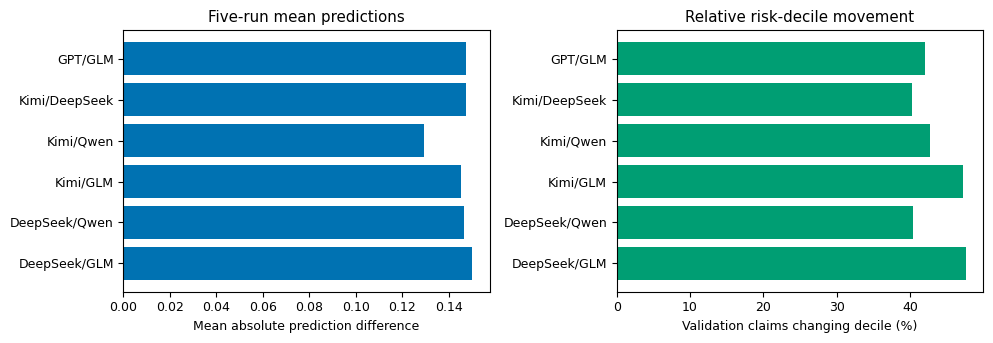

In [10]:
# Notebook-only views of Tables A4–A5; no publication figure is overwritten.
import matplotlib.pyplot as plt
from paper_reporting import SHORT
plot_pairs = primary_close_predictions
names = [f"{SHORT[r.model_a]}/{SHORT[r.model_b]}" for r in plot_pairs.itertuples()]
with plt.rc_context({"font.size": 9}):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].barh(names, plot_pairs.mean_abs_mean_prediction_difference, color="#0072B2")
    axes[0].set_xlabel("Mean absolute prediction difference")
    axes[0].set_title("Five-run mean predictions")
    axes[1].barh(names, 100 * plot_pairs.mean_prediction_risk_decile_change, color="#009E73")
    axes[1].set_xlabel("Validation claims changing decile (%)")
    axes[1].set_title("Relative risk-decile movement")
    for ax in axes:
        ax.invert_yaxis()
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Economic calibration, sparse categories, and interpretation

Dollar losses are strongly skewed. We show tail concentration and report the
separate direct-dollar Gamma fits rather than interpreting inverse-log scores as
expected dollar losses. We also compare each direct-dollar fit to its own peril-only
dollar benchmark. A dollar-MAE reduction alone is not sufficient for a reserve model:
mean calibration, squared error and tail behavior also matter. No model is tuned or
selected on this validation set, and no business action or reserve policy is observed.

**Reports:** Limitations and Table A3; additional diagnostics in SUPPLEMENT.md.


In [11]:
tail_profile = pd.DataFrame([
    {'split': split, 'claims': len(frame), 'mean_loss': frame.Loss.mean(),
     'median_loss': frame.Loss.median(), 'maximum_loss': frame.Loss.max(),
     'largest_1pct_loss_share': np.sort(frame.Loss)[-int(np.ceil(.01 * len(frame))):].sum() / frame.Loss.sum()}
    for split, frame in claims.groupby('split', sort=False)
])
tail_profile.to_csv(OUT / 'loss_tail_profile.csv', index=False)
display(tail_profile.round(4))
display(summary.query("target == 'dollars'").round(4))
display(gammas.groupby('model', sort=False).agg(
    gamma_min=('gamma', 'min'), gamma_max=('gamma', 'max'),
    model_se_min=('model_based_se', 'min'), model_se_max=('model_based_se', 'max'),
    cluster_se_min=('description_clustered_se', 'min'), cluster_se_max=('description_clustered_se', 'max'),
).round(5))


,split,claims,mean_loss,median_loss,maximum_loss,largest_1pct_loss_share
0,train,4991,19297.0543,2243.28,12922217.84,0.5555
1,validation,1039,21488.3730,3240.00,2672184.20,0.4230


,target,coding,model,mae_response,rmse_response,r2_response,normalized_gini,spearman,top_decile_lift,top_decile_loss_share,gamma_deviance_response,dollar_mae,dollar_rmse,dollar_predicted_observed
1,dollars,baseline,No LLM feature,24893.2292,111757.9706,0.0281,0.5468,0.5608,3.4484,0.3448,3.6295,24893.2292,111757.9706,0.8457
4,dollars,numeric,GPT-5.6 Sol,23580.3901,109645.1637,0.0645,0.7022,0.6624,4.8913,0.4891,2.9615,23580.3901,109645.1637,0.8733
5,dollars,categorical,GPT-5.6 Sol,24143.4179,109863.2603,0.0607,0.7068,0.6589,5.0545,0.5055,2.9470,24143.4179,109863.2603,0.9482
8,dollars,numeric,Gemini 3.1 Pro,22805.4106,109197.6474,0.0721,0.7082,0.6764,4.6300,0.4630,2.9769,22805.4106,109197.6474,0.8729
9,dollars,categorical,Gemini 3.1 Pro,23752.0334,109658.3713,0.0640,0.7229,0.6773,5.5218,0.5522,2.9931,23752.0334,109658.3713,0.9641
12,dollars,numeric,Kimi K2.6,23416.6288,109159.5693,0.0727,0.6708,0.6416,4.8665,0.4866,3.3832,23416.6288,109159.5693,0.8780
13,dollars,categorical,Kimi K2.6,24083.0834,109905.4187,0.0594,0.6809,0.6395,5.1125,0.5112,3.3844,24083.0834,109905.4187,0.9643
16,dollars,numeric,DeepSeek V4 Pro,23201.4941,110162.5811,0.0557,0.6785,0.6523,4.7101,0.4710,3.1639,23201.4941,110162.5811,0.8269
17,dollars,categorical,DeepSeek V4 Pro,23848.7311,112139.8927,0.0208,0.6841,0.6496,4.6669,0.4667,3.1934,23848.7311,112139.8927,0.8747
20,dollars,numeric,Qwen3.5 397B,23957.2724,110307.1045,0.0532,0.6620,0.6343,3.8960,0.3896,3.1620,23957.2724,110307.1045,0.8826


,gamma_min,gamma_max,model_se_min,model_se_max,cluster_se_min,cluster_se_max
model,,,,,,
GPT-5.6 Sol,0.08495,0.09311,0.00435,0.00456,0.00500,0.00693
Gemini 3.1 Pro,0.07158,0.08393,0.00373,0.00381,0.00444,0.00517
Kimi K2.6,0.07009,0.07631,0.00457,0.00491,0.00529,0.00716
DeepSeek V4 Pro,0.07022,0.07840,0.00410,0.00426,0.00455,0.00519
Qwen3.5 397B,0.05581,0.06798,0.00423,0.00438,0.00521,0.00544
GLM-5.2,0.07291,0.08115,0.00424,0.00436,0.00486,0.00580


## Reproducible manuscript tables and results

All new numerical manuscript passages and appendix tables below are generated
from the analysis objects. The existing numeric/log-response results are retained.
The appendix distinguishes inverse-log scores from direct-dollar mean fits and
prints every primary γ with both types of SE. Complete run-level coefficients,
metrics, predictions and pairwise diagnostics remain in the CSV outputs.

**Reports:** §4.2 and Appendix A.1–A.3; shared rendering uses the saved CSVs.


In [12]:
# Tables A1–A5 are rendered from the complete saved CSVs.
write_primary_appendix(PAPER, 'glm_analysis')

cp=primary_close_predictions
text=(
    '% Generated by s3_glm_extensions.ipynb.\n'
    'For H3(b), the six close-MAE pairs have five-run mean prediction differences of '
    f'{cp.mean_abs_mean_prediction_difference.min():.3f}--{cp.mean_abs_mean_prediction_difference.max():.3f} '
    'on the transformed-response scale and Spearman correlations of '
    f'{cp.prediction_spearman.min():.3f}--{cp.prediction_spearman.max():.3f}. '
    f'Relative risk deciles change for {100*cp.mean_prediction_risk_decile_change.min():.1f}--'
    f'{100*cp.mean_prediction_risk_decile_change.max():.1f}\\% of claims, but only '
    f'{100*cp.mean_prediction_risk_decile_two_plus.min():.1f}--{100*cp.mean_prediction_risk_decile_two_plus.max():.1f}\\% '
    'move at least two deciles. Across individual runs, between-model absolute differences exceed '
    "the pairs' own rerun references by "
    f'{cp.single_run_excess_mean_abs_prediction_difference.min():.3f}--'
    f'{cp.single_run_excess_mean_abs_prediction_difference.max():.3f}; all six pointwise 95\\% intervals '
    'for this excess exclude zero. The observed pattern is consistent with H3(b), while leaving '
    'financial materiality untested. Appendix Tables~\\ref{tab:prediction-differences}--'
    '\\ref{tab:prediction-run-agreement} report the core comparisons; complete pairwise results, '
    'tie sensitivities, and coefficient-locking diagnostics remain in the repository supplement.\n'
)
update_section(PAPER / 'manuscript_body.tex', 'glm_predictions', text)
print('Updated downstream prediction sections in the consolidated manuscript.')


Updated downstream prediction sections in the consolidated manuscript.


In [13]:
# Independent structural/reproduction checks, plus a manifest for analytical artifacts.
assert len(gammas) == 30 and not gammas.duplicated(['model', 'run']).any()
assert (gammas[['model_based_se', 'description_clustered_se']] > 0).all().all()
assert len(performance.query("target == 'log_loss' and coding == 'categorical'")) == 30
assert len(performance.query("target == 'dollars' and coding != 'baseline'")) == 60
assert len(validation_predictions) == len(valid) * len(performance)
assert np.isfinite(validation_predictions[['prediction_response', 'prediction_dollars']]).all().all()
assert len(category_support.query('not estimated')) == 1
assert category_support.query('not estimated').iloc[0]['model'] == 'Qwen3.5 397B'
assert int(category_support.query('not estimated').iloc[0]['run']) == 2
assert (coding_sensitivity.ci_low < 0).all() and (coding_sensitivity.ci_high > 0).all()
assert abs(coding_sensitivity.categorical_minus_numeric_mae).max() < .0012
assert len(primary_pairs) == 6
assert primary_pairs.prediction_spearman.between(0, 1).all()
assert primary_pairs.top_decile_fractional_overlap.between(0, 1).all()
assert np.isclose(primary_pairs.iloc[0].mean_abs_mean_prediction_difference,
                  np.abs(mean_predictions[('log_loss', 'numeric', primary_pairs.iloc[0].model_a)]
                         - mean_predictions[('log_loss', 'numeric', primary_pairs.iloc[0].model_b)]).mean())
artifacts = sorted(OUT.glob('*.csv')) + sorted(OUT.glob('*.json'))
manifest = pd.DataFrame([{
    'artifact': str(path.relative_to(ROOT)), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
    'bytes': path.stat().st_size,
} for path in artifacts if path.name != 'artifact_manifest.csv'])
manifest.to_csv(OUT / 'artifact_manifest.csv', index=False)
display(manifest[['artifact', 'bytes']])
print('Verified frozen inputs, all 30 original regressions, 30 gamma/SE rows, 122 Gamma fits, metric tie handling, and prediction diagnostics.')


,artifact,bytes
0,tables/glm_extensions/all_coefficients.csv,144438
1,tables/glm_extensions/categorical_support.csv,6923
2,tables/glm_extensions/coding_sensitivity.csv,1046
3,tables/glm_extensions/coefficient_locking_pred...,2477
4,tables/glm_extensions/gamma_coefficients.csv,3300
5,tables/glm_extensions/input_manifest.csv,752
6,tables/glm_extensions/loss_tail_profile.csv,213
7,tables/glm_extensions/pairwise_prediction_diag...,44002
8,tables/glm_extensions/performance_by_run.csv,34871
9,tables/glm_extensions/performance_summary.csv,6416


Verified frozen inputs, all 30 original regressions, 30 gamma/SE rows, 122 Gamma fits, metric tie handling, and prediction diagnostics.
